<a href="https://colab.research.google.com/github/emilianomtz0189/pld-monitoreo-transaccional/blob/main/notebooks/03_segmentacion_riesgo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 · Segmentación de cuentas por riesgo

**Objetivo:** dar a cada cuenta un **puntaje de riesgo** de 0 a 100 y clasificarla en nivel **bajo, medio o alto**.

**Por qué importa:** el **enfoque basado en riesgo** pide que la intensidad de los controles dependa del riesgo de cada cliente. A un cliente de riesgo alto se le aplica **debida diligencia reforzada**: más información sobre el origen de sus recursos, revisión más frecuente de su expediente y umbrales de monitoreo más estrictos. A uno de riesgo bajo, controles simplificados. Así el equipo dedica su tiempo donde más importa.

> **Referencia regulatoria (México):** las Disposiciones del art. 115 de la LIC piden a los bancos una metodología para evaluar sus riesgos de PLD (por clientes, productos y servicios, canales y zonas geográficas) y clasificar a sus clientes por **grado de riesgo**. **Verificar en el DOF** la disposición exacta y el número mínimo de niveles.

**En este notebook:**
1. Perfil de riesgo de cada cuenta con factores observables (sin la etiqueta).
2. Puntaje ponderado y niveles por percentil.
3. Evaluación: ¿los niveles altos concentran realmente las cuentas con actividad sospechosa?

## 1. Entorno

In [13]:
import os
import sys
from pathlib import Path

USUARIO_GITHUB = "emilianomtz0189"
NOMBRE_REPO = "pld-monitoreo-transaccional"
CARPETA_DRIVE = Path("/content/drive/MyDrive/pld-monitoreo-transaccional")

EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    ruta_repo = Path("/content") / NOMBRE_REPO
    if not ruta_repo.exists():
        !git clone -q https://github.com/{USUARIO_GITHUB}/{NOMBRE_REPO}.git {ruta_repo}
    else:
        !git -C {ruta_repo} pull -q
    os.chdir(ruta_repo)
else:
    CARPETA_DRIVE = None
    if Path.cwd().name == "notebooks":
        os.chdir("..")

sys.path.insert(0, str(Path.cwd()))
print("Directorio de trabajo:", Path.cwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
error: The following untracked working tree files would be overwritten by merge:
	resultados/figuras/11_segmentacion_niveles.png
	resultados/metricas/03_segmentacion.json
Please move or remove them before you merge.
Aborting
Directorio de trabajo: /content/pld-monitoreo-transaccional


In [14]:
!pip install -q -r requirements.txt

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, reglas, segmentacion
from src.datos import preparar_datos, recuperar_archivo, respaldar_resultados
from src.eda import agregar_banderas, graficar_niveles, guardar_figura, guardar_metricas

config.fijar_semilla()
config.crear_carpetas()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
METRICAS = {}

## 2. Datos

Se cargan las transacciones (etapa 1) y las alertas de las reglas (etapa 2), ambas desde el respaldo en Drive.

In [16]:
df = preparar_datos(CARPETA_DRIVE)
df = agregar_banderas(df)
df = reglas.agregar_tiempo(df)

if not recuperar_archivo(config.ARCHIVO_ALERTAS, CARPETA_DRIVE):
    raise FileNotFoundError("No se encontró alertas.parquet: ejecuta primero el notebook 02_reglas_monitoreo.")
alertas = pd.read_parquet(config.ARCHIVO_ALERTAS)
print(f"Transacciones: {len(df):,} | Alertas de la etapa 2: {len(alertas):,} | Casos (cuenta + semana): {len(alertas.drop_duplicates(['cuenta', 'semana'])):,}")

Transacciones: 9,504,852 | Alertas de la etapa 2: 249,869 | Casos (cuenta + semana): 230,508


## 3. Factores de riesgo y pesos

| Factor | Grupo de riesgo | Peso | Por qué |
|---|---|---|---|
| % de operaciones en efectivo | Canal | 25 % | El efectivo no deja rastro del origen. |
| % de operaciones internacionales | Geografía | 15 % | Más difícil rastrear origen y destino. |
| % con países en listas del GAFI | Geografía | 15 % | Jurisdicciones con deficiencias en PLD. |
| Contrapartes distintas | Transacciones | 15 % | Muchas contrapartes pueden indicar concentración o dispersión. |
| Monto total operado | Transacciones | 10 % | Mayor volumen, mayor exposición. |
| Semanas con alertas | Historial de monitoreo | 20 % | Alertas recurrentes de las reglas de la etapa 2. |

Los pesos son **criterio experto** y **no** se ajustan con la etiqueta: un banco los define en su metodología y los aprueba su comité de comunicación y control. Cada factor se convierte a su **percentil** entre todas las cuentas (0 a 1), así todos quedan en la misma escala.

In [17]:
pd.DataFrame({"peso": segmentacion.PESOS}).style.format("{:.0%}")

,peso
pct_efectivo,25%
pct_internacional,15%
pct_alto_riesgo,15%
contrapartes,15%
monto_total,10%
semanas_alertadas,20%


## 4. Perfil de cada cuenta

⏱️ Cuenta contrapartes distintas en ambos sentidos: puede tardar 1 a 3 minutos.

In [18]:
perfil = segmentacion.perfil_cuentas(df, alertas)
print(f"Cuentas: {len(perfil):,}")
perfil.describe(percentiles=[0.5, 0.9, 0.99]).T.style.format("{:,.3f}")

Cuentas: 855,460


,count,mean,std,min,50%,90%,99%,max
transacciones,"855,460.000",22.222,77.194,1.000,12.000,17.000,522.000,"1,498.000"
monto_total,"855,460.000","194,727.305","681,883.376",17.920,"74,943.256","244,713.573","4,562,380.719","19,076,962.172"
contrapartes,"855,460.000",1.965,6.494,1.000,1.000,1.000,46.000,80.000
pct_efectivo,"855,460.000",0.057,0.229,0.000,0.000,0.000,1.000,1.000
pct_internacional,"855,460.000",0.103,0.300,0.000,0.000,0.507,1.000,1.000
pct_alto_riesgo,"855,460.000",0.025,0.152,0.000,0.000,0.000,1.000,1.000
semanas_alertadas,"855,460.000",0.269,1.731,0.000,0.000,0.000,10.000,46.000
reglas_distintas,"855,460.000",0.077,0.394,0.000,0.000,0.000,2.000,6.000


## 5. Puntaje y niveles

- **Alto:** el 5 % de cuentas con mayor puntaje.
- **Medio:** el siguiente 15 %.
- **Bajo:** el 80 % restante.

Los cortes por percentil fijan la **capacidad**: cuántos clientes puede atender el equipo con debida diligencia reforzada.

In [19]:
segmentos = segmentacion.puntaje_riesgo(perfil)
cortes = segmentos.attrs["cortes"]
print(f"Corte nivel medio: {cortes['medio']:.1f} puntos | Corte nivel alto: {cortes['alto']:.1f} puntos")
segmentos["nivel"].value_counts().reindex(["bajo", "medio", "alto"]).to_frame("cuentas")

Corte nivel medio: 16.8 puntos | Corte nivel alto: 40.5 puntos


,cuentas
nivel,
bajo,684368
medio,128319
alto,42773


### ¿Cómo es una cuenta típica de cada nivel?

In [20]:
columnas = ["transacciones", "monto_total", "pct_efectivo", "pct_internacional", "pct_alto_riesgo",
            "contrapartes", "semanas_alertadas", "puntaje"]
perfil_nivel = segmentos.groupby("nivel", observed=False)[columnas].median()
perfil_nivel.style.format({"transacciones": "{:,.0f}", "monto_total": "£{:,.0f}", "pct_efectivo": "{:.1%}",
                           "pct_internacional": "{:.1%}", "pct_alto_riesgo": "{:.1%}", "contrapartes": "{:,.0f}",
                           "semanas_alertadas": "{:,.0f}", "puntaje": "{:.1f}"})

,transacciones,monto_total,pct_efectivo,pct_internacional,pct_alto_riesgo,contrapartes,semanas_alertadas,puntaje
nivel,,,,,,,,
bajo,12,"£76,777",0.0%,0.0%,0.0%,1,0,12.3
medio,12,"£28,901",0.0%,100.0%,0.0%,1,0,30.5
alto,25,"£507,692",0.5%,24.6%,3.9%,5,2,64.1


### ¿Qué factor aporta más puntos en cada nivel? (promedio de puntos)

In [21]:
puntos = segmentos.groupby("nivel", observed=False)[[f"pts_{f}" for f in segmentacion.PESOS]].mean()
puntos.columns = list(segmentacion.PESOS)
puntos.round(1)

,pct_efectivo,pct_internacional,pct_alto_riesgo,contrapartes,monto_total,semanas_alertadas
nivel,,,,,,
bajo,0.0,0.0,0.0,7.2,5.0,0.0
medio,8.6,7.6,0.6,7.7,3.9,1.3
alto,11.8,12.4,9.9,11.4,7.7,15.4


## 6. Evaluación: ¿la segmentación separa el riesgo?

Ahora sí se usa la etiqueta, **solo para evaluar**. Una cuenta es "sospechosa" si envió o recibió al menos una transacción sospechosa. Una buena segmentación pone a pocas cuentas en el nivel alto, pero ahí concentra una parte grande de las cuentas sospechosas.

> Esta evaluación es descriptiva: los factores usan todo el periodo de datos. Para medir capacidad de **predicción** sin ver el futuro está la etapa 4.

In [22]:
sospechosas = segmentacion.cuentas_sospechosas(df)
niveles = segmentacion.evaluar_niveles(segmentos, sospechosas)
METRICAS["niveles"] = niveles.round(4).reset_index().to_dict("records")
niveles.style.format({"cuentas": "{:,.0f}", "cuentas_sospechosas": "{:,.0f}", "pct_cuentas": "{:.2f}%",
                      "tasa_sospechosa_pct": "{:.3f}%", "pct_de_las_sospechosas": "{:.2f}%",
                      "veces_el_promedio": "{:.2f}x"})

,cuentas,cuentas_sospechosas,pct_cuentas,tasa_sospechosa_pct,pct_de_las_sospechosas,veces_el_promedio
nivel,,,,,,
alto,"42,773","7,069",5.00%,16.527%,89.46%,17.89x
medio,"128,319",697,15.00%,0.543%,8.82%,0.59x
bajo,"684,368",136,80.00%,0.020%,1.72%,0.02x


Gráfica guardada: resultados/figuras/11_segmentacion_niveles.png


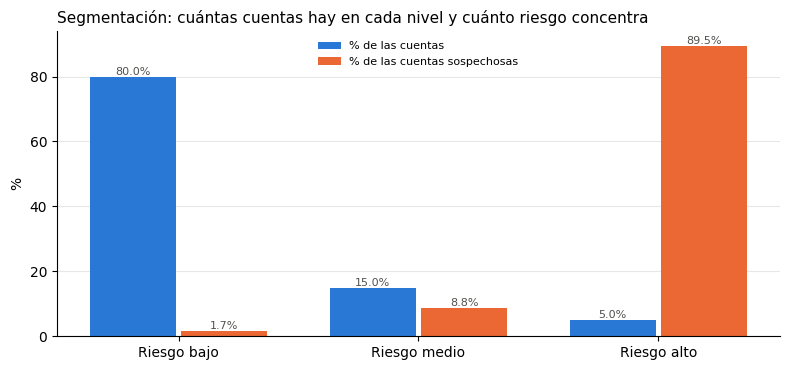

In [23]:
fig = graficar_niveles(niveles)
guardar_figura(fig, "11_segmentacion_niveles.png")
plt.show()

## 7. Guardado

In [24]:
METRICAS["pesos"] = segmentacion.PESOS
METRICAS["cortes_puntaje"] = cortes
METRICAS["cuentas"] = int(len(segmentos))
METRICAS["perfil_mediano_por_nivel"] = perfil_nivel.round(4).reset_index().to_dict("records")
guardar_metricas(METRICAS, "03_segmentacion.json")
if CARPETA_DRIVE is not None:
    respaldar_resultados(CARPETA_DRIVE)

alto, bajo = niveles.loc["alto"], niveles.loc["bajo"]
print(f'''
RESUMEN ETAPA 3
- {METRICAS["cuentas"]:,} cuentas segmentadas: alto {alto["pct_cuentas"]:.2f}% | medio {niveles.loc["medio", "pct_cuentas"]:.2f}% | bajo {bajo["pct_cuentas"]:.2f}%.
- El nivel alto concentra {alto["pct_de_las_sospechosas"]:.2f}% de las cuentas sospechosas, con {alto["veces_el_promedio"]:.2f} veces la tasa promedio.
- El nivel bajo tiene {bajo["pct_de_las_sospechosas"]:.2f}% de las cuentas sospechosas ({bajo["veces_el_promedio"]:.2f} veces la tasa promedio).
''')

Métricas guardadas: resultados/metricas/03_segmentacion.json
Resultados respaldados en /content/drive/MyDrive/pld-monitoreo-transaccional/resultados

RESUMEN ETAPA 3
- 855,460 cuentas segmentadas: alto 5.00% | medio 15.00% | bajo 80.00%.
- El nivel alto concentra 89.46% de las cuentas sospechosas, con 17.89 veces la tasa promedio.
- El nivel bajo tiene 1.72% de las cuentas sospechosas (0.02 veces la tasa promedio).



**Siguiente paso:** notebook `04_modelo_priorizacion.ipynb`: ordenar las alertas para revisar primero las más riesgosas.